<a href="https://colab.research.google.com/github/sanjaysanju2007/Dl_spam_detection/blob/main/Dl_model_spam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Initial Dataset Columns: ['v1', 'v2']
Detected label column: 'v1', text column: 'v2'
Total unique samples after dropping duplicates: 5169
label
0    0.87367
1    0.12633
Name: proportion, dtype: float64
Train size: 1157, Val size: 248, Test size: 248
Setting MAX_LEN to: 30
Calculated Class Weights: {0: np.float64(0.8264285714285714), 1: np.float64(1.2658643326039387)}


/tmp/ipykernel_429/643566139.py:75: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_sampled = df.groupby('label', group_keys=False).apply(lambda x: x.sample(n=min(len(x), 1000), random_state=42))
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 6s 44ms/step - accuracy: 0.7459 - loss: 0.6655 - val_accuracy: 0.9355 - val_loss: 0.5245
Epoch 2/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.9594 - loss: 0.2323 - val_accuracy: 0.9798 - val_loss: 0.1041
Epoch 3/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.9870 - loss: 0.0649 - val_accuracy: 0.9839 - val_loss: 0.0877
Epoch 4/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9931 - loss: 0.0318 - val_accuracy: 0.9839 - val_loss: 0.0827
Epoch 5/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9983 - loss: 0.0168 - val_accuracy: 0.9798 - val_loss: 0.0838
Epoch 6/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.9991 - loss: 0.0108 - val_accuracy: 0.9798 - val_loss: 0.0918
Epoch 7/15
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.9991 - loss: 0.0078 - val_accuracy: 0.9798 - val_loss: 0.0899


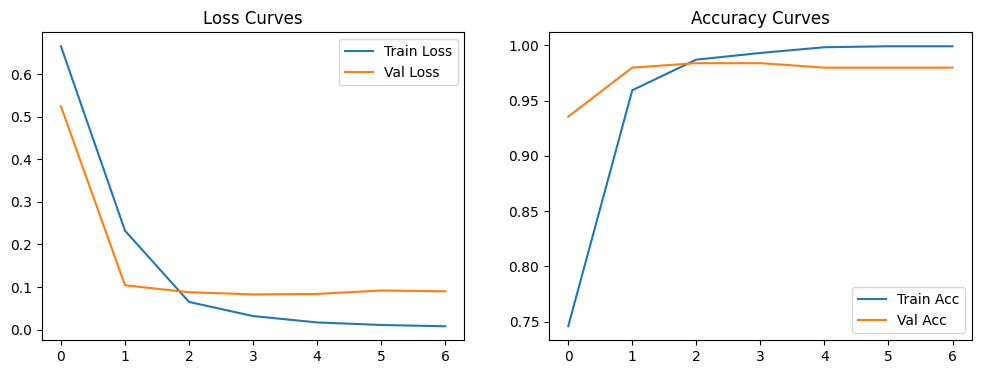

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.96      0.99      0.97       150
           1       0.99      0.93      0.96        98

    accuracy                           0.97       248
   macro avg       0.97      0.96      0.97       248
weighted avg       0.97      0.97      0.97       248

True Negative (Ham correctly flagged): 149
False Positive (Ham wrongly flagged as Spam): 1
False Negative (Spam missed): 7
True Positive (Spam correctly flagged): 91


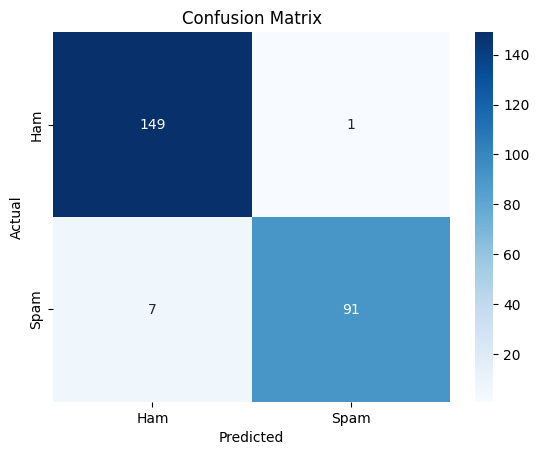


--- Live Prediction Demo ---
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
[SPAM] (Score: 1.0000) -> URGENT! Your mobile number has been awarded a £2000 prize. Call longnumber now to claim!
[SPAM] (Score: 0.9994) -> Free tickets to the Cup Final! Just text cup to longnumber to win!
[HAM] (Score: 0.0003) -> Hey, are we still meeting for lunch at 1 PM today? Let me know.
[HAM] (Score: 0.0009) -> I am going to the supermarket, do you need anything?
[SPAM] (Score: 0.9991) -> Claim your cash prize now by visiting http://spam-link.com before it expires!


In [ ]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# ==========================================
# 1. SETUP & DATA PATH
# ==========================================
DATA_PATH = "/content/spam_sms.csv"

# Load the dataset
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Please make sure the dataset is uploaded to {DATA_PATH}")

try:
    df = pd.read_csv(DATA_PATH, encoding='utf-8')
except UnicodeDecodeError:
    df = pd.read_csv(DATA_PATH, encoding='latin-1')

print("Initial Dataset Columns:", df.columns.tolist())

# Standardize column names
# Standard Kaggle SMS spam datasets typically have 'v1' (label) and 'v2' (text) or 'Category' and 'Message'
possible_label_cols = ['v1', 'Category', 'label', 'class', 'type']
possible_text_cols = ['v2', 'Message', 'text', 'sms', 'sms_text']

label_col = next((c for c in df.columns if c in possible_label_cols), df.columns[0])
text_col = next((c for c in df.columns if c in possible_text_cols), df.columns[1])

print(f"Detected label column: '{label_col}', text column: '{text_col}'")

# Clean and drop unneeded columns
df = df[[label_col, text_col]].dropna()
df.columns = ['label', 'text']

# Drop duplicates to prevent train/test leakage
df = df.drop_duplicates().reset_index(drop=True)

# Map labels to binary values (0 = ham, 1 = spam)
df['label'] = df['label'].astype(str).str.lower().map({'ham': 0, 'spam': 1, '0': 0, '1': 1})
print(f"Total unique samples after dropping duplicates: {len(df)}")
print(df['label'].value_counts(normalize=True))

# ==========================================
# 2. TEXT PREPROCESSING
# ==========================================
def clean_text(text):
    text = str(text).lower()
    # Replace URLs with generic token
    text = re.sub(r'https?://\S+|www\.\S+', 'urltoken', text)
    # Replace money/prices (e.g. £1000, $500, etc.)
    text = re.sub(r'[£$€]\d+', 'moneytoken', text)
    # Replace long sequences of digits (phone numbers, codes)
    text = re.sub(r'\d{5,}', 'longnumber', text)
    # Remove remaining digits and standard punctuation
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    return text

df['cleaned_text'] = df['text'].apply(clean_text)

# Stratified sample to match approximately ~2000 rows if dataset is larger, keeping class ratio
if len(df) > 2000:
    df_sampled = df.groupby('label', group_keys=False).apply(lambda x: x.sample(n=min(len(x), 1000), random_state=42))
else:
    df_sampled = df

# Train/Val/Test Split (70/15/15 stratified)
X = df_sampled['cleaned_text'].values
y = df_sampled['label'].values

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print(f"Train size: {len(X_train)}, Val size: {len(X_val)}, Test size: {len(X_test)}")

# ==========================================
# 3. TOKENIZATION & PADDING
# ==========================================
MAX_WORDS = 5000
tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

# Determine padding length based on 95th percentile
train_lengths = [len(seq) for seq in tokenizer.texts_to_sequences(X_train)]
MAX_LEN = int(np.percentile(train_lengths, 95)) if len(train_lengths) > 0 else 50
print(f"Setting MAX_LEN to: {MAX_LEN}")

X_train_seq = pad_sequences(tokenizer.texts_to_sequences(X_train), maxlen=MAX_LEN, padding='post')
X_val_seq = pad_sequences(tokenizer.texts_to_sequences(X_val), maxlen=MAX_LEN, padding='post')
X_test_seq = pad_sequences(tokenizer.texts_to_sequences(X_test), maxlen=MAX_LEN, padding='post')

# Compute class weights
class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {i : class_weights[i] for i in range(len(class_weights))}
print("Calculated Class Weights:", class_weight_dict)

# ==========================================
# 4. MODEL ARCHITECTURE & TRAINING
# ==========================================
model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=64, input_length=MAX_LEN, mask_zero=True),
    GRU(64, dropout=0.2),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])

model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_seq, y_train,
    validation_data=(X_val_seq, y_val),
    epochs=15,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping],
    verbose=1
)

# ==========================================
# 5. EVALUATION
# ==========================================
# Plot Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(history.history['loss'], label='Train Loss')
ax1.plot(history.history['val_loss'], label='Val Loss')
ax1.set_title('Loss Curves')
ax1.legend()

ax2.plot(history.history['accuracy'], label='Train Acc')
ax2.plot(history.history['val_accuracy'], label='Val Acc')
ax2.set_title('Accuracy Curves')
ax2.legend()
plt.savefig('training_curves.png')
plt.show()

# Test Predictions
y_pred_prob = model.predict(X_test_seq).squeeze()
y_pred = (y_pred_prob >= 0.5).astype(int)

# Metrics
print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"True Negative (Ham correctly flagged): {tn}")
print(f"False Positive (Ham wrongly flagged as Spam): {fp}")
print(f"False Negative (Spam missed): {fn}")
print(f"True Positive (Spam correctly flagged): {tp}")

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.savefig('confusion_matrix.png')
plt.show()

# ==========================================
# 6. DEMO PREDICTION ON NEW MESSAGES
# ==========================================
def predict_sms(messages, threshold=0.5):
    cleaned = [clean_text(m) for m in messages]
    seqs = tokenizer.texts_to_sequences(cleaned)
    padded = pad_sequences(seqs, maxlen=MAX_LEN, padding='post')
    probs = model.predict(padded).squeeze()

    # Handle single element edge-case
    if len(messages) == 1:
        probs = [probs]

    for msg, prob in zip(messages, probs):
        pred_label = "SPAM" if prob >= threshold else "HAM"
        print(f"[{pred_label}] (Score: {prob:.4f}) -> {msg}")

test_messages = [
    "URGENT! Your mobile number has been awarded a £2000 prize. Call longnumber now to claim!",
    "Free tickets to the Cup Final! Just text cup to longnumber to win!",
    "Hey, are we still meeting for lunch at 1 PM today? Let me know.",
    "I am going to the supermarket, do you need anything?",
    "Claim your cash prize now by visiting http://spam-link.com before it expires!"
]

print("\n--- Live Prediction Demo ---")
predict_sms(test_messages)

Dataset shape: (5572, 2)
Columns: ['v1', 'v2']

Samples: 2000
label
Ham     1751
Spam     249
Name: count, dtype: int64


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 100, 64)        │       250,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 100, 64)        │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 277,569 (1.06 MB)

 Trainable params: 277,569 (1.06 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 14s 140ms/step - accuracy: 0.4750 - loss: 0.6769 - val_accuracy: 0.6281 - val_loss: 0.6664 - learning_rate: 0.0010
Epoch 2/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 8s 92ms/step - accuracy: 0.9047 - loss: 0.3025 - val_accuracy: 0.9656 - val_loss: 0.1734 - learning_rate: 0.0010
Epoch 3/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 133ms/step - accuracy: 0.9930 - loss: 0.0799 - val_accuracy: 0.9688 - val_loss: 0.1321 - learning_rate: 0.0010
Epoch 4/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 94ms/step - accuracy: 0.9969 - loss: 0.0367 - val_accuracy: 0.9656 - val_loss: 0.1378 - learning_rate: 0.0010
Epoch 5/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step - accuracy: 0.9979 - loss: 0.0195
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 128ms/step - accuracy: 0.9984 - loss: 0.0160 - val_accuracy: 0.9656 - val_loss: 0.1399 - learning_rate: 0.0010
Epoch 6/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 88ms/step - accuracy: 1.0000 - loss: 0.0081 - val

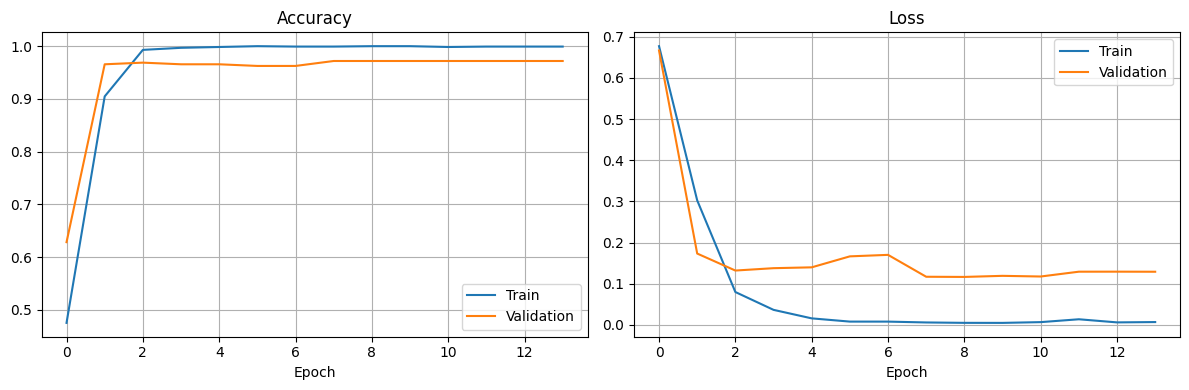


Selected threshold: 0.77

========== FINAL TEST RESULTS ==========
Accuracy : 0.9875
Precision: 0.9245
Recall   : 0.9800
F1-score : 0.9515

Classification Report:
              precision    recall  f1-score   support

         Ham       1.00      0.99      0.99       350
        Spam       0.92      0.98      0.95        50

    accuracy                           0.99       400
   macro avg       0.96      0.98      0.97       400
weighted avg       0.99      0.99      0.99       400



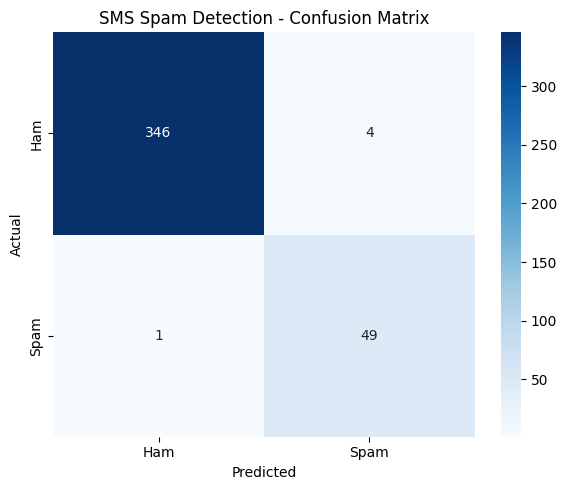


Message: Congratulations! You won a free prize. Call now!
Prediction: SPAM
Spam probability: 99.90%

Message: Hey, are we meeting at college tomorrow?
Prediction: HAM
Spam probability: 0.15%

Message: URGENT! Your account is blocked. Click to verify.
Prediction: HAM
Spam probability: 69.54%

Message: Please send me the class notes.
Prediction: HAM
Spam probability: 0.96%

Model, tokenizer, config and confusion matrix saved!


In [ ]:
# SMS SPAM DETECTION USING BIDIRECTIONAL LSTM

import os
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, Bidirectional, LSTM, Dense,
    Dropout, SpatialDropout1D
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# 1. Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# 2. Load dataset
file_path = "/content/spam_sms.csv"

if not os.path.exists(file_path):
    from google.colab import files
    uploaded = files.upload()
    csv_files = [f for f in uploaded if f.lower().endswith(".csv")]
    if not csv_files:
        raise ValueError("Please upload your SMS dataset CSV.")
    file_path = csv_files[0]

try:
    df = pd.read_csv(file_path, encoding="utf-8")
except UnicodeDecodeError:
    df = pd.read_csv(file_path, encoding="latin-1")

df.columns = [str(c).strip().lower() for c in df.columns]
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

# 3. Identify text and label columns
label_candidates = ["v1", "label", "category", "class", "type", "target"]
text_candidates = ["v2", "text", "message", "sms", "sms_text"]

label_col = next((c for c in label_candidates if c in df.columns), None)
text_col = next((c for c in text_candidates if c in df.columns), None)

if label_col is None or text_col is None:
    # Fallback for datasets with different column names
    for col in df.columns:
        values = set(df[col].dropna().astype(str).str.lower().str.strip().unique())
        if values and values.issubset({"ham", "spam", "0", "1"}):
            label_col = col
            break

    remaining = [
        c for c in df.columns
        if c != label_col and not c.startswith("unnamed")
    ]
    if text_col is None and remaining:
        text_col = max(
            remaining,
            key=lambda c: df[c].astype(str).str.len().mean()
        )

if label_col is None or text_col is None or label_col == text_col:
    raise ValueError("Cannot identify columns. Check df.head() and set label_col/text_col.")

data = df[[label_col, text_col]].copy()
data.columns = ["label", "message"]
data = data.dropna()
data["message"] = data["message"].astype(str).str.strip()
data["label"] = data["label"].astype(str).str.lower().str.strip()
data = data[data["message"] != ""]

# Normalize labels
mapping = {
    "ham": 0, "not spam": 0, "legitimate": 0,
    "0": 0, "spam": 1, "1": 1
}
data["label"] = data["label"].map(mapping)
data = data.dropna(subset=["label"])
data["label"] = data["label"].astype(int)
data = data.drop_duplicates(subset=["message"]).reset_index(drop=True)

if data["label"].nunique() != 2:
    raise ValueError("Dataset must contain both ham and spam labels.")

# 4. Select approximately 2,000 balanced-proportion samples
if len(data) > 2000:
    data, _ = train_test_split(
        data,
        train_size=2000,
        random_state=SEED,
        stratify=data["label"]
    )

data = data.reset_index(drop=True)
print("\nSamples:", len(data))
print(data["label"].map({0: "Ham", 1: "Spam"}).value_counts())

# 5. Preprocess text
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()

X = data["message"].apply(clean_text).to_numpy()
y = data["label"].to_numpy()

# 6. Train, validation and test splits
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.20, random_state=SEED, stratify=y_train_val
)

# 7. Tokenization and padding
MAX_WORDS = 10000
MAX_LEN = 100

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

def encode_text(texts):
    return pad_sequences(
        tokenizer.texts_to_sequences(texts),
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

X_train_seq = encode_text(X_train)
X_val_seq = encode_text(X_val)
X_test_seq = encode_text(X_test)

vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)

# 8. Class weights for imbalanced data
classes = np.unique(y_train)
weights = compute_class_weight(
    class_weight="balanced", classes=classes, y=y_train
)
class_weights = dict(zip(classes, weights))

# 9. Build Bidirectional LSTM
model = Sequential([
    tf.keras.Input(shape=(MAX_LEN,)),
    Embedding(vocab_size, 64, mask_zero=True),
    SpatialDropout1D(0.20),
    Bidirectional(LSTM(32, dropout=0.20)),
    Dense(32, activation="relu"),
    Dropout(0.40),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# 10. Train model
callbacks = [
    EarlyStopping(
        monitor="val_loss", patience=5,
        restore_best_weights=True, verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss", factor=0.5,
        patience=2, min_lr=1e-5, verbose=1
    )
]

history = model.fit(
    X_train_seq, y_train,
    validation_data=(X_val_seq, y_val),
    epochs=30,
    batch_size=32,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

# 11. Plot training curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.xlabel("Epoch")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# 12. Select threshold using validation data only
val_prob = model.predict(X_val_seq, verbose=0).ravel()
thresholds = np.arange(0.20, 0.81, 0.01)

best_threshold = 0.5
best_f1 = -1

for threshold in thresholds:
    val_pred = (val_prob >= threshold).astype(int)
    score = f1_score(y_val, val_pred, zero_division=0)
    if score > best_f1:
        best_f1 = score
        best_threshold = threshold

print(f"\nSelected threshold: {best_threshold:.2f}")

# 13. Final test evaluation
test_prob = model.predict(X_test_seq, verbose=0).ravel()
y_pred = (test_prob >= best_threshold).astype(int)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred, zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Ham", "Spam"],
    zero_division=0
))

# 14. Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)
plt.title("SMS Spam Detection - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

# 15. Predict new messages
def predict_sms(message):
    seq = encode_text([clean_text(message)])
    probability = float(model.predict(seq, verbose=0)[0][0])
    result = "SPAM" if probability >= best_threshold else "HAM"
    print("\nMessage:", message)
    print("Prediction:", result)
    print(f"Spam probability: {probability:.2%}")
    return result

predict_sms("Congratulations! You won a free prize. Call now!")
predict_sms("Hey, are we meeting at college tomorrow?")
predict_sms("URGENT! Your account is blocked. Click to verify.")
predict_sms("Please send me the class notes.")

# 16. Save model and tokenizer
import pickle
import json

model.save("sms_spam_lstm.keras")

with open("sms_tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

with open("config.json", "w") as f:
    json.dump({
        "max_len": MAX_LEN,
        "threshold": float(best_threshold),
        "model_type": "Bidirectional LSTM"
    }, f, indent=4)

print("\nModel, tokenizer, config and confusion matrix saved!")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Load dataset
df = pd.read_csv("/content/spam_sms.csv", encoding="latin-1")

print(df.head())
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

     v1                                                 v2
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Dataset shape: (5572, 2)
Columns: ['v1', 'v2']


In [ ]:
# Select the message and label columns
df = df.iloc[:, :2].copy()
df.columns = ["label", "message"]

# Remove missing and duplicate messages
df = df.dropna()
df = df.drop_duplicates(subset=["message"])

# Convert labels into numbers
df["label"] = df["label"].astype(str).str.lower().str.strip()

df["label"] = df["label"].map({
    "ham": 0,
    "spam": 1,
    "0": 0,
    "1": 1
})

df = df.dropna(subset=["label"])
df["label"] = df["label"].astype(int)

# Use 2,000 messages
if len(df) > 2000:
    df, _ = train_test_split(
        df, train_size=2000,
        random_state=42, stratify=df["label"]
    )

print("Total messages:", len(df))
print(df["label"].value_counts())

Total messages: 2000
label
0    1747
1     253
Name: count, dtype: int64


In [ ]:
X = df["message"].astype(str)
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))

Training messages: 1600
Testing messages: 400


In [ ]:
tokenizer = Tokenizer(num_words=5000, oov_token="<OOV>")

# Learn vocabulary from training messages only
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq, maxlen=100, padding="post", truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq, maxlen=100, padding="post", truncating="post"
)

print("Training data shape:", X_train_pad.shape)
print("Testing data shape:", X_test_pad.shape)

Training data shape: (1600, 100)
Testing data shape: (400, 100)


In [ ]:
model = Sequential([
    Embedding(input_dim=5000, output_dim=32, mask_zero=True),
    LSTM(32),
    Dropout(0.3),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 13s 95ms/step - accuracy: 0.8594 - loss: 0.5708 - val_accuracy: 0.8781 - val_loss: 0.3962
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.9008 - loss: 0.2424 - val_accuracy: 0.9563 - val_loss: 0.1577
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - accuracy: 0.9805 - loss: 0.1067 - val_accuracy: 0.9719 - val_loss: 0.1101
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - accuracy: 0.9937 - loss: 0.0407 - val_accuracy: 0.9656 - val_loss: 0.1045
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.9969 - loss: 0.0197 - val_accuracy: 0.9688 - val_loss: 0.1313
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.9992 - loss: 0.0073 - val_accuracy: 0.9688 - val_loss: 0.1102
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 1.0000 - loss: 0.0049 - val_accuracy: 0.9719 - val_loss: 0.1246


In [ ]:
probabilities = model.predict(X_test_pad).ravel()
predictions = (probabilities >= 0.5).astype(int)

print("Accuracy :", accuracy_score(y_test, predictions))
print("Precision:", precision_score(y_test, predictions, zero_division=0))
print("Recall   :", recall_score(y_test, predictions, zero_division=0))
print("F1-score :", f1_score(y_test, predictions, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test, predictions,
    target_names=["Ham", "Spam"],
    zero_division=0
))

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
Accuracy : 0.9625
Precision: 0.8333333333333334
Recall   : 0.8823529411764706
F1-score : 0.8571428571428571

Classification Report:
              precision    recall  f1-score   support

         Ham       0.98      0.97      0.98       349
        Spam       0.83      0.88      0.86        51

    accuracy                           0.96       400
   macro avg       0.91      0.93      0.92       400
weighted avg       0.96      0.96      0.96       400



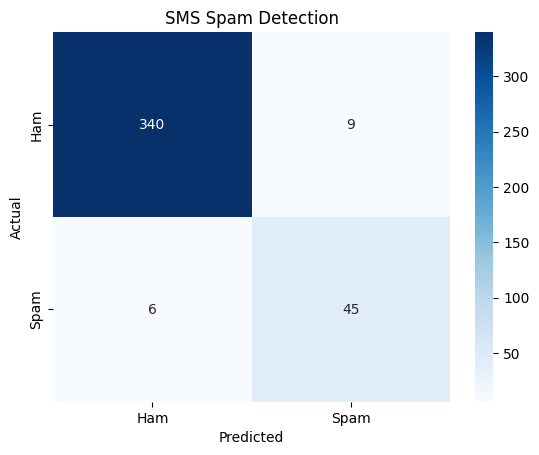

In [ ]:
cm = confusion_matrix(y_test, predictions, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SMS Spam Detection")
plt.show()

In [ ]:
def predict_sms(message):
    sequence = tokenizer.texts_to_sequences([message])

    padded = pad_sequences(
        sequence,
        maxlen=100,
        padding="post",
        truncating="post"
    )

    probability = model.predict(padded, verbose=0)[0][0]

    if probability >= 0.5:
        print("SPAM MESSAGE")
    else:
        print("NORMAL MESSAGE")

    print("Spam probability:", round(float(probability) * 100, 2), "%")


predict_sms("Congratulations! You won a free prize. Call now!")
predict_sms("Hello, are you coming to college tomorrow?")
predict_sms("URGENT! Claim your cash reward now!")

SPAM MESSAGE
Spam probability: 93.25 %
NORMAL MESSAGE
Spam probability: 0.76 %
SPAM MESSAGE
Spam probability: 84.38 %


In [ ]:
import os
import shutil
from google.colab import files

# 1. Create the output directory
output_dir = "sms_spam_outputs"
os.makedirs(output_dir, exist_ok=True)

# 2. Move or copy your generated files into the folder
# (adjust filenames based on what you actually generated in your notebook)
files_to_save = ["confusion_matrix.png", "training_curves.png"]
for file_name in files_to_save:
    if os.path.exists(file_name):
        shutil.copy(file_name, os.path.join(output_dir, file_name))

print("Files in output directory:", os.listdir(output_dir))

# 3. Archive and trigger download
shutil.make_archive(output_dir, "zip", output_dir)
files.download(f"{output_dir}.zip")

Files in output directory: ['training_curves.png', 'confusion_matrix.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>